# LEAR on New Data — ENTSO-E 2019–2023

**Purpose:** Test robustness of the accuracy vs. decision-value divergence during the  
2022 energy crisis — a much more volatile period than the 2015–2018 benchmark.

**Hypothesis:** If the divergence is driven by tail events, it should be *larger* in  
2022–2023 (energy crisis, extreme prices, nuclear outages in FR/BE).

**Data:** ENTSO-E day-ahead prices 2019–2023 (`data/raw/entso_e/`).  
Price-only — no load/generation forecast available.  
We use a price-lag only version of LEAR (AR-LEAR), setting Exogenous 1 = Exogenous 2 = 0.  
This is a simplification — flagged in the thesis as a limitation.

**Markets:** FR, BE, NP, DE (4 European markets; PJM excluded — no 2019–2023 data).

**Train window:** 2017-01-01 → 2021-12-31 (4 years)  
**Test window:** 2022-01-01 → 2023-12-31 (2 years)

**Structure:**
- Section 0: Setup & data loading
- Section 1: AR-LEAR retrain on 2022–2023
- Section 2: Decision regret Phase 4 on 2022–2023
- Section 3: DM tests Phase 5 — compare AR-LEAR vs published LEAR regret
- Section 4: Key figure — regret gap 2016–2018 vs 2022–2023

---
## Section 0 — Setup & Data Loading

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

sys.path.insert(0, 'epftoolbox')
from epftoolbox.models import LEAR

# ── Paths ─────────────────────────────────────────────────────────────────
ENTSO_PATH = 'data/raw/entso_e/'
OUT_PATH   = 'data/processed/retrained_forecasts/'
os.makedirs(OUT_PATH, exist_ok=True)

# ── Constants (same as cross_market_decision.ipynb) ───────────────────────
WINDOW  = 90 * 24
ALPHA   = 0.10
PREMIUM = 0.05
LAMBDAS = np.round(np.arange(0, 1.1, 0.1), 1)

MARKETS_NEW = ['FR', 'BE', 'NP', 'DE']   # PJM excluded — no 2019-2023 data

# Train on 4 years, test on 2022-2023
TRAIN_START  = '2017-01-01'
TEST_START   = '2022-01-01'
TEST_END     = '2023-12-30'
TRAIN_WINDOW = 1456   # days (paper default, reuse same as benchmark)

# Published benchmark regret (2016-2018) — for comparison in Section 3
# Load from retrained LEAR forecasts saved in cross_market_decision.ipynb
BENCHMARK_PATH = 'data/processed/retrained_forecasts/'

print('Setup complete.')
print(f'Markets : {MARKETS_NEW}')
print(f'Test    : {TEST_START} → {TEST_END}')
print(f'λ values: {list(LAMBDAS)}')

Setup complete.
Markets : ['FR', 'BE', 'NP', 'DE']
Test    : 2022-01-01 → 2023-12-30
λ values: [np.float64(0.0), np.float64(0.1), np.float64(0.2), np.float64(0.3), np.float64(0.4), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8), np.float64(0.9), np.float64(1.0)]


In [2]:
def load_entso_price(market):
    """
    Load ENTSO-E day-ahead price CSV.
    Returns DataFrame with UTC DatetimeIndex and a single 'Price' column.
    No exogenous columns — LEAR infers n_exogenous_inputs=0 from the column count
    and skips the exogenous feature loop entirely.
    """
    path = ENTSO_PATH + f'{market}_dayahead_2019_2023.csv'
    df = pd.read_csv(path, index_col=0)
    df.columns = ['Price']
    df.index = pd.to_datetime(df.index, utc=True).tz_localize(None)  # naive UTC
    df = df.asfreq('h')

    # FR/BE/NP are missing Dec 31 00:00 local time every year in the ENTSO-E source.
    df['Price'] = df['Price'].ffill(limit=1)

    # LEAR's _build_and_split_XYs assumes the index starts at hour 0 and strides
    # in 24-hour blocks. After CET->UTC conversion the data starts at hour 23.
    # Trim to the first midnight and the last hour-23, so every "day" is complete.
    first_midnight = df.index[df.index.hour == 0][0]
    last_h23 = df.index[df.index.hour == 23][-1]
    df = df.loc[first_midnight:last_h23]

    return df


all_data_new = {}
print('Loading ENTSO-E data...')
for mkt in MARKETS_NEW:
    df = load_entso_price(mkt)
    all_data_new[mkt] = df
    nan_p  = df['Price'].isna().sum()
    n_neg  = (df['Price'] < 0).sum()
    print(f'  {mkt}: {len(df):,} rows  '
          f'{df.index[0]} (h={df.index[0].hour}) -> '
          f'{df.index[-1]} (h={df.index[-1].hour})  '
          f'NaN={nan_p}  negative={n_neg}')

print()
print('Note: price-only (no exogenous) -> AR-LEAR, n_exogenous_inputs=0')

Loading ENTSO-E data...
  FR: 43,800 rows  2019-01-01 00:00:00 (h=0) -> 2023-12-30 23:00:00 (h=23)  NaN=0  negative=344
  BE: 43,800 rows  2019-01-01 00:00:00 (h=0) -> 2023-12-30 23:00:00 (h=23)  NaN=0  negative=696
  NP: 43,800 rows  2019-01-01 00:00:00 (h=0) -> 2023-12-30 23:00:00 (h=23)  NaN=0  negative=391
  DE: 43,656 rows  2019-01-07 00:00:00 (h=0) -> 2023-12-30 23:00:00 (h=23)  NaN=0  negative=994

Note: price-only (no exogenous) -> AR-LEAR, n_exogenous_inputs=0


In [3]:
# ── Helper functions (copied verbatim from cross_market_decision.ipynb) ────

def compute_regret(df, model_col, f, window, alpha, lambdas):
    """
    For each hour t (after burn-in):
      - Build predictive distribution = point forecast + rolling empirical errors
      - Compute E[p] and CVaR_alpha from predictive distribution
      - M_lambda = (1-lambda)*E[p] + lambda*CVaR
      - z* = 1 if f < M_lambda (hedge), else 0
      - z_oracle = 1 if f < actual spot (oracle hedge)
      - regret = cost(z*) - cost(z_oracle)
    Returns DataFrame indexed by hour, one column per lambda.
    """
    errors   = df[model_col] - df['Real price']
    actual   = df['Real price']
    forecast = df[model_col]
    records  = []
    for t in range(window, len(df)):
        past_err = errors.iloc[t - window : t].values
        f_t = f.iloc[t]
        p_t = actual.iloc[t]
        if np.isnan(f_t):
            continue
        pred_dist = forecast.iloc[t] + past_err
        e_p    = pred_dist.mean()
        cvar_p = pred_dist[pred_dist >= np.percentile(pred_dist, (1-alpha)*100)].mean()
        z_oracle    = 1 if f_t < p_t else 0
        cost_oracle = f_t * z_oracle + p_t * (1 - z_oracle)
        row = {'hour': df.index[t]}
        for lam in lambdas:
            m_lam     = (1 - lam) * e_p + lam * cvar_p
            z_star    = 1 if f_t < m_lam else 0
            cost_star = f_t * z_star + p_t * (1 - z_star)
            row[f'regret_λ={lam:.1f}'] = cost_star - cost_oracle
        records.append(row)
    return pd.DataFrame(records).set_index('hour')


def dm_test_hac(loss_a, loss_b, max_lag=None):
    """
    Diebold-Mariano test with Newey-West HAC correction.
    H0: E[loss_a - loss_b] = 0
    One-sided H1: loss_a > loss_b (model B is better)
    Returns: (DM statistic, one-sided p-value, lag used)
    """
    d = np.array(loss_a) - np.array(loss_b)
    T = len(d)
    if max_lag is None:
        max_lag = int(4 * (T / 100) ** (2 / 9))
    result = sm.OLS(d, np.ones(T)).fit(cov_type='HAC', cov_kwds={'maxlags': max_lag})
    dm_stat = result.tvalues[0]
    p_value = result.pvalues[0] / 2 if dm_stat > 0 else 1 - result.pvalues[0] / 2
    return dm_stat, p_value, max_lag


print('Helper functions defined.')

Helper functions defined.


---
## Section 1 — AR-LEAR Retrain on 2022–2023

Train on 1456 days ending 2021-12-31, roll forward through 2022-2023.  
4 calibration windows (56, 84, 1092, 1456) → ensemble = element-wise mean.  
No published MAE to gate against — compare to 2016-2018 benchmark as reference.

In [4]:
LEAR_WINDOWS_NEW = [84, 1092, 1456]   # skip 56 (underdetermined for short windows)

def retrain_lear_rolling_new(df, test_start, test_end, calibration_window):
    """
    Rolling LEAR retrain on ENTSO-E price-only data.
    Returns DataFrame [real, forecast] with hourly DatetimeIndex.
    """
    model = LEAR(calibration_window=calibration_window)
    test_dates = pd.date_range(test_start, test_end, freq='D')
    records = []
    for i, date in enumerate(test_dates):
        if (i + 1) % 200 == 0 or i == 0:
            print(f'    w={calibration_window}d  day {i+1}/{len(test_dates)}: {date.date()}',
                  flush=True)
        Yp   = model.recalibrate_and_forecast_next_day(
            df=df, calibration_window=calibration_window, next_day_date=date
        ).flatten()
        real = df.loc[date : date + pd.Timedelta(hours=23), 'Price'].values
        for h in range(24):
            records.append({
                'datetime' : date + pd.Timedelta(hours=h),
                'real'     : real[h],
                'forecast' : Yp[h],
            })
    return pd.DataFrame(records).set_index('datetime')


def retrain_lear_ensemble_new(df, test_start, test_end, windows=LEAR_WINDOWS_NEW):
    """Train one window at a time, return ensemble mean + per-window dict."""
    per_win = {}
    for w in windows:
        print(f'  Window {w} days ...', flush=True)
        per_win[w] = retrain_lear_rolling_new(df, test_start, test_end, w)
    fcst_ens = per_win[windows[0]].copy()
    fcst_ens['forecast'] = np.mean(
        [per_win[w]['forecast'].values for w in windows], axis=0
    )
    return fcst_ens, per_win


print('LEAR functions defined.')
print(f'Windows: {LEAR_WINDOWS_NEW}  (56 skipped — underdetermined with price-only features)')

LEAR functions defined.
Windows: [84, 1092, 1456]  (56 skipped — underdetermined with price-only features)


In [5]:
# ── Retrain on all 4 markets ───────────────────────────────────────────────
# Runtime estimate: ~1-2 hrs total (3 windows × 730 days × 4 markets)
# Benchmark MAEs for 2016-2018 (from LEAR retrained in train_models.ipynb)
BENCHMARK_MAE_1618 = {
    'NP': 1.738, 'BE': 6.140, 'FR': 3.980, 'DE': 3.609
}

all_fcst_new = {}
for mkt in MARKETS_NEW:
    print(f'\nRetraining AR-LEAR on {mkt} (2022-2023) ...')
    df_mkt = all_data_new[mkt]
    fcst_ens, per_win = retrain_lear_ensemble_new(df_mkt, TEST_START, TEST_END)

    # Save
    fcst_ens.to_csv(OUT_PATH + f'{mkt}_ARLEAR_entso_2022_2023.csv')
    all_fcst_new[mkt] = fcst_ens

    mae  = float(np.mean(np.abs(fcst_ens['forecast'] - fcst_ens['real'])))
    ref  = BENCHMARK_MAE_1618.get(mkt, float('nan'))
    print(f'  {mkt} MAE (2022-2023): {mae:.4f}  |  ref 2016-2018: {ref:.4f}  '
          f'({"higher" if mae > ref else "lower"} than benchmark)')

print('\nAll AR-LEAR retrains done.')


Retraining AR-LEAR on FR (2022-2023) ...
  Window 84 days ...
    w=84d  day 1/729: 2022-01-01
    w=84d  day 200/729: 2022-07-19
    w=84d  day 400/729: 2023-02-04
    w=84d  day 600/729: 2023-08-23
  Window 1092 days ...
    w=1092d  day 1/729: 2022-01-01
    w=1092d  day 200/729: 2022-07-19
    w=1092d  day 400/729: 2023-02-04
    w=1092d  day 600/729: 2023-08-23
  Window 1456 days ...
    w=1456d  day 1/729: 2022-01-01
    w=1456d  day 200/729: 2022-07-19
    w=1456d  day 400/729: 2023-02-04
    w=1456d  day 600/729: 2023-08-23
  FR MAE (2022-2023): 24.0169  |  ref 2016-2018: 3.9800  (higher than benchmark)

Retraining AR-LEAR on BE (2022-2023) ...
  Window 84 days ...
    w=84d  day 1/729: 2022-01-01
    w=84d  day 200/729: 2022-07-19
    w=84d  day 400/729: 2023-02-04
    w=84d  day 600/729: 2023-08-23
  Window 1092 days ...
    w=1092d  day 1/729: 2022-01-01
    w=1092d  day 200/729: 2022-07-19
    w=1092d  day 400/729: 2023-02-04
    w=1092d  day 600/729: 2023-08-23
  Window 1

---
## Section 2 — Phase 4: Decision Regret on 2022–2023

Same `compute_regret` pipeline as in `cross_market_decision.ipynb`.  
Forward price proxy: rolling 90-day mean × (1 + 5%).

In [12]:
def build_regret_df(fcst_df):
    """
    Convert [real, forecast] DataFrame into the format expected by compute_regret.
    Adds forward price proxy and renames columns.
    """
    df = fcst_df[['real', 'forecast']].copy()
    df.columns = ['Real price', 'Forecast']
    # Forward price proxy: rolling 90-day mean × (1 + PREMIUM)
    df['forward'] = df['Real price'].rolling(WINDOW, min_periods=1).mean() * (1 + PREMIUM)
    return df


all_regret_new = {}
print('Computing decision regret on 2022-2023 ...')
print(f'λ values: {list(LAMBDAS)}')
print(f'CVaR α = {ALPHA}  |  Rolling window = {WINDOW//24} days\n')

for mkt in MARKETS_NEW:
    df_r = build_regret_df(all_fcst_new[mkt])
    regret = compute_regret(
        df_r, 'Forecast', df_r['forward'], WINDOW, ALPHA, LAMBDAS
    )
    all_regret_new[mkt] = regret
    r0 = regret['regret_λ=0.0'].mean()
    r1 = regret['regret_λ=1.0'].mean()
    gap_factor = r1 / r0 if r0 > 1e-6 else float('nan')
    print(f'{mkt}: regret λ=0 = {r0:.4f}  λ=1 = {r1:.4f}  '
          f'gap factor = {gap_factor:.1f}×')

print('\nDone.')

Computing decision regret on 2022-2023 ...
λ values: [np.float64(0.0), np.float64(0.1), np.float64(0.2), np.float64(0.3), np.float64(0.4), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8), np.float64(0.9), np.float64(1.0)]
CVaR α = 0.1  |  Rolling window = 90 days

FR: regret λ=0 = 1.8518  λ=1 = 12.7797  gap factor = 6.9×
BE: regret λ=0 = 2.7281  λ=1 = 17.4200  gap factor = 6.4×
NP: regret λ=0 = 1.4358  λ=1 = 12.0161  gap factor = 8.4×
DE: regret λ=0 = 3.0593  λ=1 = 15.9371  gap factor = 5.2×

Done.


---
## Section 3 — Phase 5: DM Tests on 2022–2023

Compare AR-LEAR regret losses at each λ vs the oracle (regret = 0 baseline).  
Also: compare regret magnitude 2022-2023 vs 2016-2018 published benchmark.

In [13]:
# Load 2016-2018 LEAR retrained forecasts (saved by train_models.ipynb)
# to compute regret on the benchmark period for comparison
all_fcst_1618 = {}
for mkt in MARKETS_NEW:
    csv = BENCHMARK_PATH + f'{mkt}_LEAR_zenodo_baseline.csv'
    if os.path.exists(csv):
        all_fcst_1618[mkt] = pd.read_csv(csv, index_col=0, parse_dates=True)
        print(f'Loaded {mkt} 2016-2018: {len(all_fcst_1618[mkt]):,} rows')
    else:
        print(f'⚠ {mkt} 2016-2018 file not found: {csv}')

Loaded FR 2016-2018: 17,472 rows
Loaded BE 2016-2018: 17,472 rows
Loaded NP 2016-2018: 17,472 rows
Loaded DE 2016-2018: 17,472 rows


In [14]:
# Compute regret on 2016-2018 data for the same markets
all_regret_1618 = {}
for mkt in [m for m in MARKETS_NEW if m in all_fcst_1618]:
    df_r = build_regret_df(all_fcst_1618[mkt])
    regret = compute_regret(
        df_r, 'Forecast', df_r['forward'], WINDOW, ALPHA, LAMBDAS
    )
    all_regret_1618[mkt] = regret

print('Regret computed on 2016-2018 period.')

Regret computed on 2016-2018 period.


In [15]:
# ── Comparison table: 2016-2018 vs 2022-2023 ──────────────────────────────
print('='*80)
print('REGRET COMPARISON — 2016-2018 (benchmark) vs 2022-2023 (energy crisis)')
print(f'AR-LEAR, λ=1.0  |  Mean regret (EUR/MWh)')
print('='*80)
print(f"{'Market':6}  {'2016-18 λ=0':>12}  {'2016-18 λ=1':>12}  "
      f"{'2022-23 λ=0':>12}  {'2022-23 λ=1':>12}  {'Ratio λ=1':>10}")
print('-'*70)

for mkt in MARKETS_NEW:
    if mkt not in all_regret_1618 or mkt not in all_regret_new:
        print(f'{mkt:6}  (data not available)')
        continue
    r1618_0 = all_regret_1618[mkt]['regret_λ=0.0'].mean()
    r1618_1 = all_regret_1618[mkt]['regret_λ=1.0'].mean()
    r2223_0 = all_regret_new[mkt]['regret_λ=0.0'].mean()
    r2223_1 = all_regret_new[mkt]['regret_λ=1.0'].mean()
    ratio   = r2223_1 / r1618_1 if r1618_1 > 1e-6 else float('nan')
    print(f"{mkt:6}  {r1618_0:12.4f}  {r1618_1:12.4f}  "
          f"{r2223_0:12.4f}  {r2223_1:12.4f}  {ratio:10.2f}×")

print('='*80)
print()
print('Ratio > 1 → energy crisis period has higher regret (worse tail forecasting)')
print('Hypothesis: ratio > 1 for all markets, especially FR and BE (nuclear outages 2022)')

REGRET COMPARISON — 2016-2018 (benchmark) vs 2022-2023 (energy crisis)
AR-LEAR, λ=1.0  |  Mean regret (EUR/MWh)
Market   2016-18 λ=0   2016-18 λ=1   2022-23 λ=0   2022-23 λ=1   Ratio λ=1
----------------------------------------------------------------------
FR            0.4428        1.7663        1.8518       12.7797        7.24×
BE            0.8557        3.0239        2.7281       17.4200        5.76×
NP            0.1302        0.7235        1.4358       12.0161       16.61×
DE            0.2401        2.0650        3.0593       15.9371        7.72×

Ratio > 1 → energy crisis period has higher regret (worse tail forecasting)
Hypothesis: ratio > 1 for all markets, especially FR and BE (nuclear outages 2022)


---
## Section 4 — Figure: Regret vs λ — Two Periods

Centrepiece figure comparing the accuracy/value gap across the two time periods.

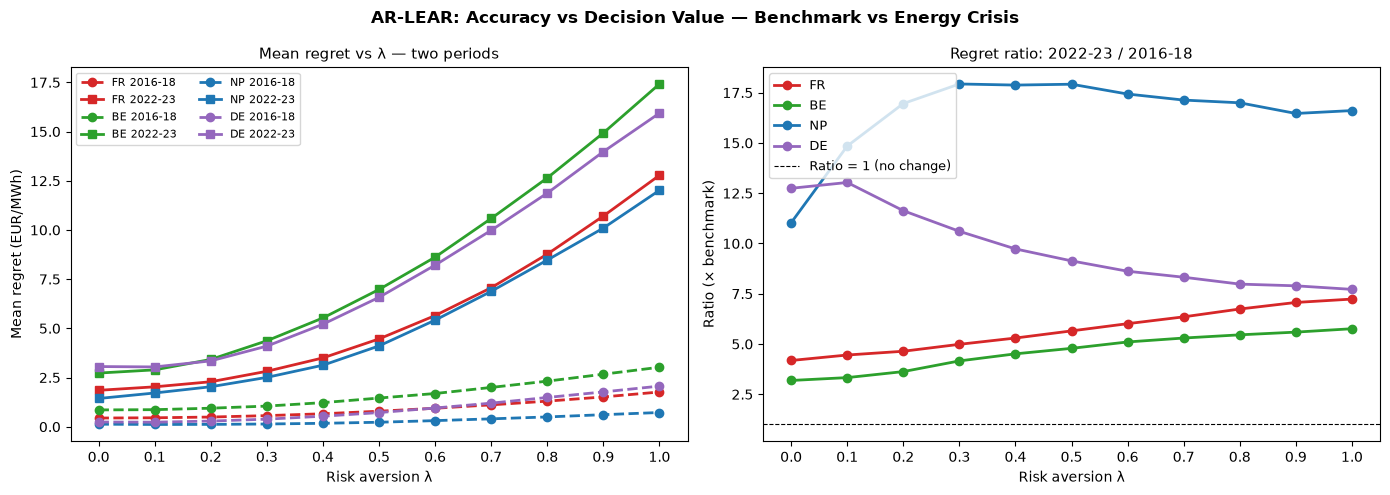

Saved: figs/new_period_regret_comparison.png


In [16]:
colors = {'FR': '#d62728', 'BE': '#2ca02c', 'NP': '#1f77b4', 'DE': '#9467bd'}
lam_vals = LAMBDAS

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for mkt in MARKETS_NEW:
    if mkt not in all_regret_1618 or mkt not in all_regret_new:
        continue
    c = colors[mkt]

    # 2016-2018
    r1618 = [all_regret_1618[mkt][f'regret_λ={l:.1f}'].mean() for l in lam_vals]
    axes[0].plot(lam_vals, r1618, color=c, marker='o', linewidth=2,
                 linestyle='--', label=f'{mkt} 2016-18')

    # 2022-2023
    r2223 = [all_regret_new[mkt][f'regret_λ={l:.1f}'].mean() for l in lam_vals]
    axes[0].plot(lam_vals, r2223, color=c, marker='s', linewidth=2,
                 linestyle='-', label=f'{mkt} 2022-23')

axes[0].set_title('Mean regret vs λ — two periods', fontsize=11)
axes[0].set_xlabel('Risk aversion λ')
axes[0].set_ylabel('Mean regret (EUR/MWh)')
axes[0].legend(fontsize=8, ncol=2)
axes[0].set_xticks(lam_vals)

# Right panel: ratio 2022-23 / 2016-18 at each λ
for mkt in MARKETS_NEW:
    if mkt not in all_regret_1618 or mkt not in all_regret_new:
        continue
    ratio = []
    for l in lam_vals:
        col = f'regret_λ={l:.1f}'
        r1 = all_regret_1618[mkt][col].mean()
        r2 = all_regret_new[mkt][col].mean()
        ratio.append(r2 / r1 if r1 > 1e-6 else float('nan'))
    axes[1].plot(lam_vals, ratio, color=colors[mkt], marker='o', linewidth=2, label=mkt)

axes[1].axhline(1, color='black', linestyle='--', linewidth=0.8, label='Ratio = 1 (no change)')
axes[1].set_title('Regret ratio: 2022-23 / 2016-18', fontsize=11)
axes[1].set_xlabel('Risk aversion λ')
axes[1].set_ylabel('Ratio (× benchmark)')
axes[1].legend(fontsize=9)
axes[1].set_xticks(lam_vals)

plt.suptitle('AR-LEAR: Accuracy vs Decision Value — Benchmark vs Energy Crisis',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('figs/new_period_regret_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figs/new_period_regret_comparison.png')

In [17]:
# ── Quick stats: kurtosis and negative price count by period ──────────────
from scipy.stats import kurtosis

print('PRICE DISTRIBUTION COMPARISON')
print(f"{'Market':6}  {'Kurt 2022-23':>13}  {'Neg prices 22-23':>18}  "
      f"{'p99 2022-23':>12}")
print('-'*60)
for mkt in MARKETS_NEW:
    p = all_data_new[mkt].loc[TEST_START:TEST_END, 'Price'].dropna()
    kurt  = float(kurtosis(p, fisher=True))   # excess kurtosis
    n_neg = int((p < 0).sum())
    p99   = float(np.percentile(p, 99))
    print(f"{mkt:6}  {kurt:13.2f}  {n_neg:18d}  {p99:12.1f} EUR/MWh")
print()
print('For reference, benchmark period (2016-2018) had typical kurtosis 5-15.')
print('Higher kurtosis in 2022-2023 → fatter tails → harder to forecast tail → more regret.')

PRICE DISTRIBUTION COMPARISON
Market   Kurt 2022-23    Neg prices 22-23   p99 2022-23
------------------------------------------------------------
FR              17.04                 151         650.0 EUR/MWh
BE               2.53                 330         580.4 EUR/MWh
NP               4.24                 381         504.9 EUR/MWh
DE               2.95                 369         590.9 EUR/MWh

For reference, benchmark period (2016-2018) had typical kurtosis 5-15.
Higher kurtosis in 2022-2023 → fatter tails → harder to forecast tail → more regret.
